# Comparing Distributions

In [1]:
# datascience
from datascience import *
import numpy as np

%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')

In [2]:
# polars
import polars as pl
from IPython.display import display
import numpy as np

def _append(base, extra):
    """Append a value or a Series onto a Series."""
    extra_s = extra if isinstance(extra, pl.Series) else pl.Series([extra])
    if base.len() == 0:
        return extra_s
    if base.dtype != extra_s.dtype:
        try:
            extra_s = extra_s.cast(base.dtype, strict=False)
        except Exception:
            base = base.cast(extra_s.dtype, strict=False)
    return pl.concat([base, extra_s])

def sample_proportions_pl(sample_size, proportions):
    """Draw `sample_size` items from `proportions` and return each category's share.

    A category that is not drawn stays 0. Polars `sample` has no weights, so the
    draw uses `np.random.choice`.
    """
    proportions = list(proportions)
    categories = list(range(len(proportions)))
    drawn = np.random.choice(categories, size=sample_size, p=proportions)
    counts = pl.Series("drawn", drawn).value_counts()
    count_dict = dict(zip(counts["drawn"].to_list(), counts["count"].to_list()))
    return [count_dict.get(cat, 0) / sample_size for cat in categories]


## Alameda County Jury Panels ##

In [3]:
# datascience
jury = Table().with_columns(
    'Ethnicity', make_array('Asian', 'Black', 'Latino', 'White', 'Other'),
    'Eligible', make_array(0.15, 0.18, 0.12, 0.54, 0.01),
    'Panels', make_array(0.26, 0.08, 0.08, 0.54, 0.04)
)

jury

Ethnicity,Eligible,Panels
Asian,0.15,0.26
Black,0.18,0.08
Latino,0.12,0.08
White,0.54,0.54
Other,0.01,0.04


In [4]:
# polars
jury_pl = pl.DataFrame({'Ethnicity': pl.Series("values", ['Asian', 'Black', 'Latino', 'White', 'Other']), 'Eligible': pl.Series("values", [0.15, 0.18, 0.12, 0.54, 0.01]), 'Panels': pl.Series("values", [0.26, 0.08, 0.08, 0.54, 0.04])})

jury_pl

Ethnicity,Eligible,Panels
str,f64,f64
"""Asian""",0.15,0.26
"""Black""",0.18,0.08
"""Latino""",0.12,0.08
"""White""",0.54,0.54
"""Other""",0.01,0.04


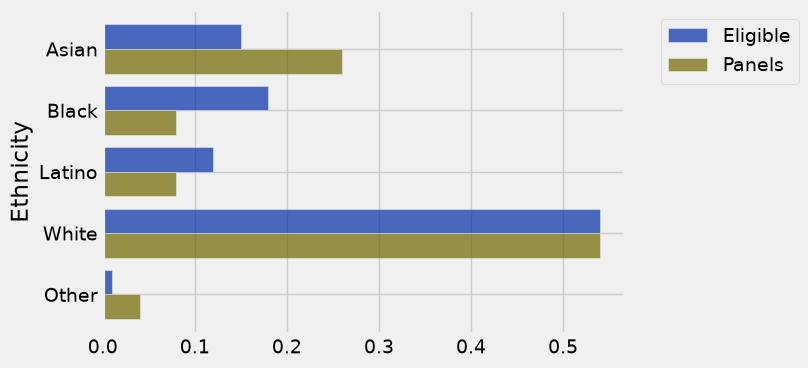

In [5]:
# datascience
jury.barh('Ethnicity')

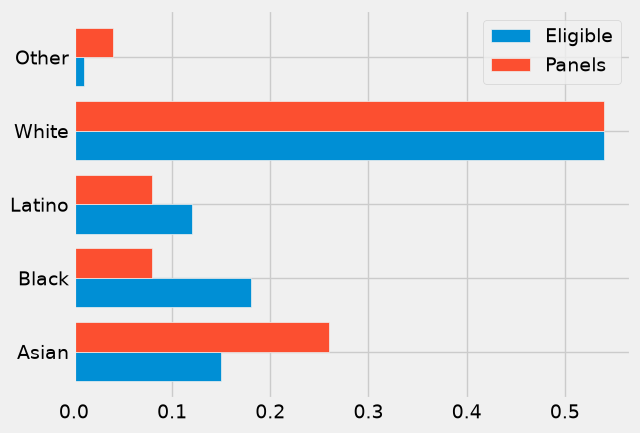

In [6]:
# polars
# matplotlib
_df = jury_pl
_cat = 'Ethnicity'
_vals = [c for c in _df.columns if c != _cat and _df[c].dtype.is_numeric()]
if len(_vals) == 1:
    plots.barh(_df.get_column(_cat).to_list(), _df.get_column(_vals[0]).to_list())
    plots.xlabel(_vals[0])
else:
    _n = len(_vals)
    _y = list(range(_df.height))
    _h = 0.8 / _n
    for _i, _c in enumerate(_vals):
        plots.barh([y + _i * _h for y in _y], _df.get_column(_c).to_list(), height=_h, label=_c)
    plots.yticks([y + _h * (_n - 1) / 2 for y in _y], _df.get_column(_cat).to_list())
    plots.legend()

In [7]:
# datascience
# Under the model, this is the true distribution of people
# from which the jurors are randomly sampled
model = jury.column('Eligible')

In [8]:
# polars
# Under the model, this is the true distribution of people
# from which the jurors are randomly sampled
model_pl = jury_pl.get_column('Eligible')

In [9]:
# datascience
# Let's simulate a random draw of 1423 jurors from this distribution
simulated = sample_proportions(1423, model)
simulated

array([ 0.1468728 ,  0.18341532,  0.13281799,  0.52775826,  0.00913563])

In [10]:
#polars_with_ss_imported
from datascience import sample_proportions
# POLARS_CHANGE: sample_proportions returns an array; store it as a Series
# Let's simulate a random draw of 1423 jurors from this distribution
simulated_pl = pl.Series("draw", sample_proportions(1423, list(model_pl)))
simulated_pl

draw
f64
0.128602
0.184821
0.126493
0.54884
0.011244


In [11]:
#polars-with-helper
# POLARS_CHANGE: sample_proportions returns an array; store it as a Series
# Let's simulate a random draw of 1423 jurors from this distribution
simulated_pl = pl.Series("draw", sample_proportions_pl(1423, list(model_pl)))
simulated_pl

draw
f64
0.173577
0.170766
0.111736
0.536191
0.00773


In [12]:
# datascience
# The actual observed distribution (Panels) looks quite different
# from the simulation -- try running this several times to confirm!
jury_with_simulated = jury.with_column('Simulated', simulated)
jury_with_simulated

Ethnicity,Eligible,Panels,Simulated
Asian,0.15,0.26,0.146873
Black,0.18,0.08,0.183415
Latino,0.12,0.08,0.132818
White,0.54,0.54,0.527758
Other,0.01,0.04,0.00913563


In [13]:
# polars
# The actual observed distribution (Panels) looks quite different
# from the simulation -- try running this several times to confirm!
jury_with_simulated_pl = jury_pl.with_columns(pl.Series('Simulated', simulated_pl))
jury_with_simulated_pl

Ethnicity,Eligible,Panels,Simulated
str,f64,f64,f64
"""Asian""",0.15,0.26,0.173577
"""Black""",0.18,0.08,0.170766
"""Latino""",0.12,0.08,0.111736
"""White""",0.54,0.54,0.536191
"""Other""",0.01,0.04,0.00773


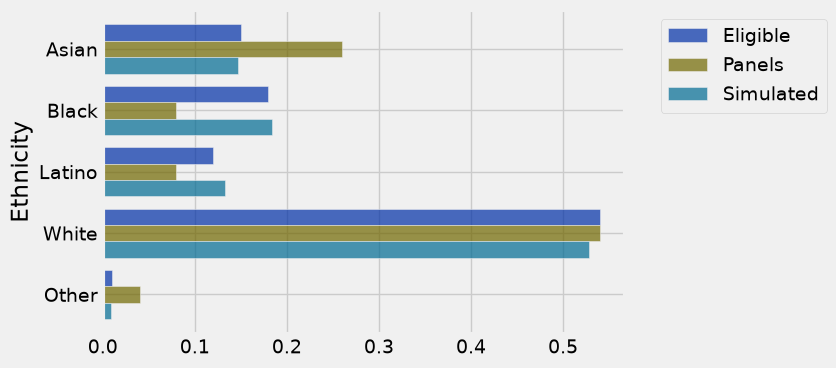

In [14]:
# datascience
jury_with_simulated.barh('Ethnicity')

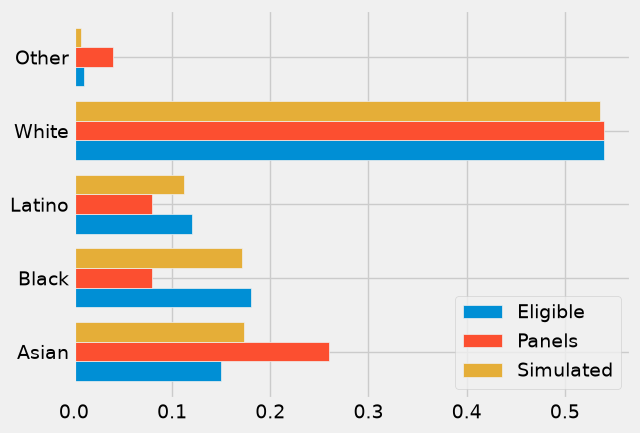

In [15]:
# polars
# matplotlib
_df = jury_with_simulated_pl
_cat = 'Ethnicity'
_vals = [c for c in _df.columns if c != _cat and _df[c].dtype.is_numeric()]
if len(_vals) == 1:
    plots.barh(_df.get_column(_cat).to_list(), _df.get_column(_vals[0]).to_list())
    plots.xlabel(_vals[0])
else:
    _n = len(_vals)
    _y = list(range(_df.height))
    _h = 0.8 / _n
    for _i, _c in enumerate(_vals):
        plots.barh([y + _i * _h for y in _y], _df.get_column(_c).to_list(), height=_h, label=_c)
    plots.yticks([y + _h * (_n - 1) / 2 for y in _y], _df.get_column(_cat).to_list())
    plots.legend()

**DISCUSS**: What do you see?

## Distance Between Distributions

In [16]:
# datascience
# In the last lecture, the difference between observed black/purple
# and their expected values (26%/75%) was our statistic.
#
# In this case, we need to understand how each of the 5 categories
# differ from their expected values according to the model.

diffs = jury.column('Panels') - jury.column('Eligible')
jury_with_difference = jury.with_column('Difference', diffs)
jury_with_difference

Ethnicity,Eligible,Panels,Difference
Asian,0.15,0.26,0.11
Black,0.18,0.08,-0.1
Latino,0.12,0.08,-0.04
White,0.54,0.54,0
Other,0.01,0.04,0.03


In [17]:
# polars
# In the last lecture, the difference between observed black/purple
# and their expected values (26%/75%) was our statistic.
#
# In this case, we need to understand how each of the 5 categories
# differ from their expected values according to the model.

diffs_pl = jury_pl.get_column('Panels') - jury_pl.get_column('Eligible')
jury_with_difference_pl = jury_pl.with_columns(pl.Series('Difference', diffs_pl))
jury_with_difference_pl

Ethnicity,Eligible,Panels,Difference
str,f64,f64,f64
"""Asian""",0.15,0.26,0.11
"""Black""",0.18,0.08,-0.1
"""Latino""",0.12,0.08,-0.04
"""White""",0.54,0.54,0.0
"""Other""",0.01,0.04,0.03


## Total Variation Distance

In [18]:
def tvd(dist1, dist2):
    return sum(abs(dist1 - dist2))/2

In [19]:
# datascience
# The TVD of our observed data (Panels) from their expected values
#                                            if the model were true (Eligible)

model = jury.column('Eligible')
obsvd_tvd = tvd(jury.column('Panels'), model)
obsvd_tvd

0.14000000000000001

In [20]:
# polars
# The TVD of our observed data (Panels) from their expected values
#                                            if the model were true (Eligible)

model_pl = jury_pl.get_column('Eligible')
obsvd_tvd_pl = tvd(jury_pl.get_column('Panels'), model_pl)
obsvd_tvd_pl

0.14

In [21]:
# datascience
# The TVD of a model simluation from its expected values
tvd(sample_proportions(1423, model), jury.column('Eligible'))

0.0065706254392129109

In [22]:
#polars_with_ss_imported
from datascience import sample_proportions
# POLARS_CHANGE: sample_proportions returns an array; store it as a Series
# The TVD of a model simluation from its expected values
tvd(pl.Series("draw", sample_proportions(1423, list(model_pl))), jury_pl.get_column('Eligible'))

0.009430780042164471

In [23]:
#polars-with-helper
# POLARS_CHANGE: sample_proportions returns an array; store it as a Series
# The TVD of a model simluation from its expected values
tvd(pl.Series("draw", sample_proportions_pl(1423, list(model_pl))), jury_pl.get_column('Eligible'))

0.01712579058327474

In [24]:
# datascience
def simulated_tvd():
    return tvd(sample_proportions(1423, model), model)

tvds = make_array()

num_simulations = 10000
for i in np.arange(num_simulations):
    new_tvd = simulated_tvd()
    tvds = np.append(tvds, new_tvd)

In [25]:
#polars_with_ss_imported
from datascience import sample_proportions
# POLARS_CHANGE: sample_proportions returns an array; store it as a Series
def simulated_tvd_pl():
    return tvd(pl.Series("draw", sample_proportions(1423, list(model_pl))), model_pl)

tvds_pl = []

num_simulations_pl = 10000
for i in pl.int_range(num_simulations_pl, eager=True):
    new_tvd = simulated_tvd_pl()
    tvds_pl.append(new_tvd)
tvds_pl = pl.Series("values", tvds_pl)

In [26]:
#polars-with-helper
# POLARS_CHANGE: sample_proportions returns an array; store it as a Series
def simulated_tvd_pl():
    return tvd(pl.Series("draw", sample_proportions_pl(1423, list(model_pl))), model_pl)

tvds_pl = []

num_simulations_pl = 10000
for i in pl.int_range(num_simulations_pl, eager=True):
    new_tvd = simulated_tvd_pl()
    tvds_pl.append(new_tvd)
tvds_pl = pl.Series("values", tvds_pl)

Observed TVD: 0.14


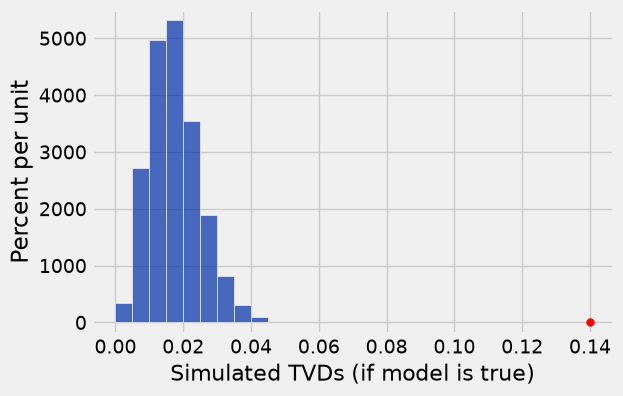

In [27]:
# datascience
title = 'Simulated TVDs (if model is true)'
bins = np.arange(0, .05, .005)

Table().with_column(title, tvds).hist(bins = bins)
print('Observed TVD: ' + str(obsvd_tvd))

# Plotting details; ignore this code
plots.ylim(-2, 55)
plots.scatter(obsvd_tvd, 0, color='red', s=30);

Observed TVD: 0.14


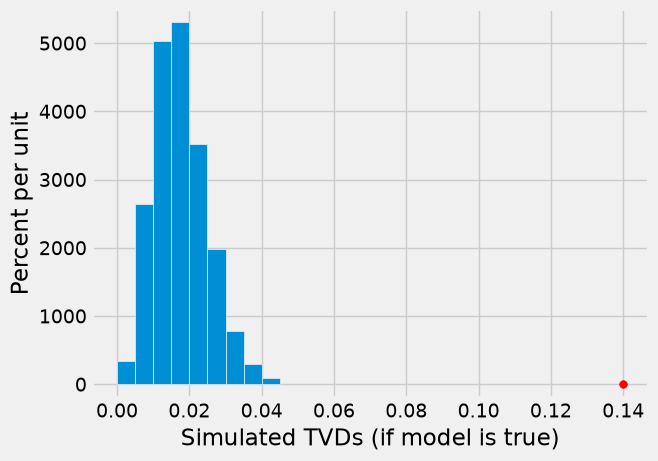

In [28]:
# polars
# matplotlib
title_pl = 'Simulated TVDs (if model is true)'
bins_pl = pl.linear_space(0.0, 0.045, 10, closed="both", eager=True)

_df = pl.DataFrame({title_pl: tvds_pl})
_cols = [c for c in _df.columns if _df[c].dtype.is_numeric()]
if len(_cols) == 1:
    plots.hist(_df.get_column(_cols[0]).to_numpy(), density=True, bins=(lambda _b: _b.to_numpy() if hasattr(_b, 'to_numpy') else _b)(bins_pl))
    plots.xlabel(_cols[0])
else:
    for _col in _cols:
        plots.hist(_df.get_column(_col).to_numpy(), density=True, label=_col, bins=(lambda _b: _b.to_numpy() if hasattr(_b, 'to_numpy') else _b)(bins_pl))
    plots.legend()
plots.ylabel("Percent per unit")
plots.gca().yaxis.set_major_formatter(lambda x, pos: "{:g}".format(100 * x))
print('Observed TVD: ' + str(obsvd_tvd_pl))

# Plotting details; ignore this code
plots.ylim(-2, 55)
plots.scatter(obsvd_tvd_pl, 0, color='red', s=30);

## Be the Jury Program

In [29]:
# datascience
# Counts are from the 88% of participants in Be the Jury in 2023 who completed the exit survey and shared their race

sf = Table().with_columns(
    'Race/Ethnicity',
    ['American Indian or Alaska Native',
     'Asian',
     'Black or African American',
     'Hispanic or Latino',
     'Native Hawaiian or Other Pacific Islander',
     'Some Other Race',
     'White'],
    'Count',[4, 168,23,59,4,5,175],
    'SF Census (2020)', [0.005, 0.3440, 0.0520, 0.1540, 0.0040, 0.0490, 0.3920])
sf.set_format(2, PercentFormatter)

Race/Ethnicity,Count,SF Census (2020)
American Indian or Alaska Native,4,0.50%
Asian,168,34.40%
Black or African American,23,5.20%
Hispanic or Latino,59,15.40%
Native Hawaiian or Other Pacific Islander,4,0.40%
Some Other Race,5,4.90%
White,175,39.20%


In [30]:
# polars
# Counts are from the 88% of participants in Be the Jury in 2023 who completed the exit survey and shared their race

sf_pl = pl.DataFrame({'Race/Ethnicity': ['American Indian or Alaska Native',
     'Asian',
     'Black or African American',
     'Hispanic or Latino',
     'Native Hawaiian or Other Pacific Islander',
     'Some Other Race',
     'White'], 'Count': [4, 168,23,59,4,5,175], 'SF Census (2020)': [0.005, 0.3440, 0.0520, 0.1540, 0.0040, 0.0490, 0.3920]})
sf_pl

Race/Ethnicity,Count,SF Census (2020)
str,i64,f64
"""American Indian or Alaska Nati…",4,0.005
"""Asian""",168,0.344
"""Black or African American""",23,0.052
"""Hispanic or Latino""",59,0.154
"""Native Hawaiian or Other Pacif…",4,0.004
"""Some Other Race""",5,0.049
"""White""",175,0.392


In [31]:
# datascience
sum(sf.column('Count'))

438

In [32]:
# polars
sum(sf_pl.get_column('Count'))

438

In [33]:
# datascience
sf = (sf.with_column('Panels', sf.column('Count') / sum(sf.column('Count')))
        .relabeled('SF Census (2020)', 'Eligible'))
sf.set_format(3, PercentFormatter)

Race/Ethnicity,Count,Eligible,Panels
American Indian or Alaska Native,4,0.50%,0.91%
Asian,168,34.40%,38.36%
Black or African American,23,5.20%,5.25%
Hispanic or Latino,59,15.40%,13.47%
Native Hawaiian or Other Pacific Islander,4,0.40%,0.91%
Some Other Race,5,4.90%,1.14%
White,175,39.20%,39.95%


In [34]:
# polars
sf_pl = (sf_pl.with_columns(pl.Series('Panels', sf_pl.get_column('Count') / sum(sf_pl.get_column('Count')))).rename({'SF Census (2020)': 'Eligible'}))
sf_pl

Race/Ethnicity,Count,Eligible,Panels
str,i64,f64,f64
"""American Indian or Alaska Nati…",4,0.005,0.009132
"""Asian""",168,0.344,0.383562
"""Black or African American""",23,0.052,0.052511
"""Hispanic or Latino""",59,0.154,0.134703
"""Native Hawaiian or Other Pacif…",4,0.004,0.009132
"""Some Other Race""",5,0.049,0.011416
"""White""",175,0.392,0.399543


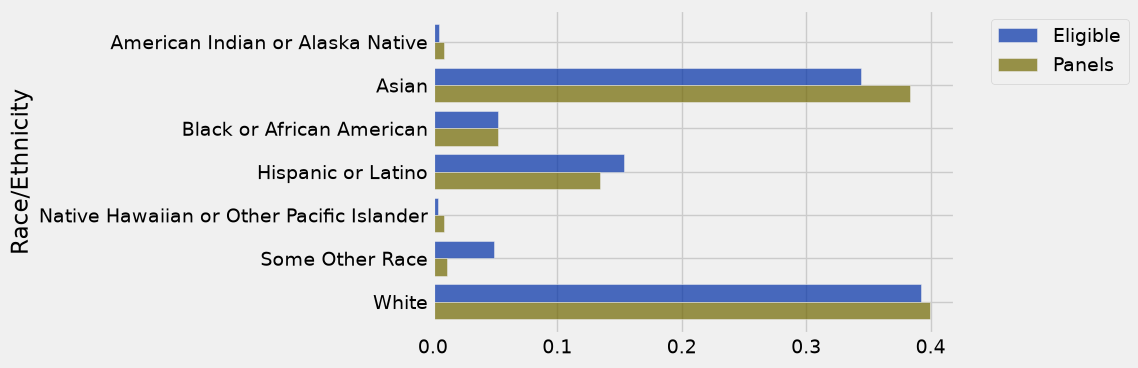

In [35]:
# datascience
sf.select(0, 2, 3).barh(0)

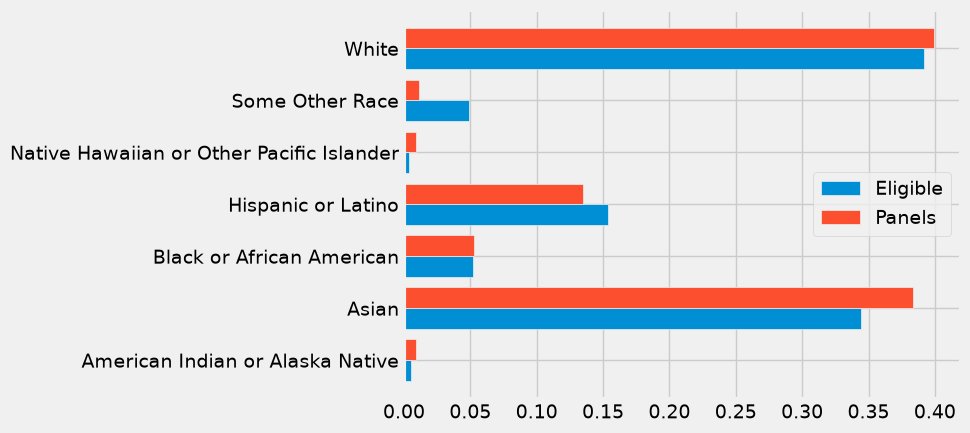

In [36]:
# polars
# matplotlib
_df = sf_pl.select(pl.nth(0), pl.nth(2), pl.nth(3))
_cat = _df.columns[0]
_vals = [c for c in _df.columns if c != _cat and _df[c].dtype.is_numeric()]
if len(_vals) == 1:
    plots.barh(_df.get_column(_cat).to_list(), _df.get_column(_vals[0]).to_list())
    plots.xlabel(_vals[0])
else:
    _n = len(_vals)
    _y = list(range(_df.height))
    _h = 0.8 / _n
    for _i, _c in enumerate(_vals):
        plots.barh([y + _i * _h for y in _y], _df.get_column(_c).to_list(), height=_h, label=_c)
    plots.yticks([y + _h * (_n - 1) / 2 for y in _y], _df.get_column(_cat).to_list())
    plots.legend()

In [37]:
# datascience
jury = sf
obsvd_tvd = tvd(jury.column('Panels'), jury.column('Eligible'))
obsvd_tvd

0.056881278538812786

In [38]:
# polars
jury_pl = sf_pl
obsvd_tvd_pl = tvd(jury_pl.get_column('Panels'), jury_pl.get_column('Eligible'))
obsvd_tvd_pl

0.056881278538812786

In [39]:
# datascience
def simulated_tvd():
    return tvd(sample_proportions(438, model), model)

tvds = make_array()

num_simulations = 10000
for i in np.arange(num_simulations):
    new_tvd = simulated_tvd()
    tvds = np.append(tvds, new_tvd)

In [40]:
#polars_with_ss_imported
from datascience import sample_proportions
# POLARS_CHANGE: sample_proportions returns an array; store it as a Series
def simulated_tvd_pl():
    return tvd(pl.Series("draw", sample_proportions(438, list(model_pl))), model_pl)

tvds_pl = []

num_simulations_pl = 10000
for i in pl.int_range(num_simulations_pl, eager=True):
    new_tvd = simulated_tvd_pl()
    tvds_pl.append(new_tvd)
tvds_pl = pl.Series("values", tvds_pl)

In [41]:
#polars-with-helper
# POLARS_CHANGE: sample_proportions returns an array; store it as a Series
def simulated_tvd_pl():
    return tvd(pl.Series("draw", sample_proportions_pl(438, list(model_pl))), model_pl)

tvds_pl = []

num_simulations_pl = 10000
for i in pl.int_range(num_simulations_pl, eager=True):
    new_tvd = simulated_tvd_pl()
    tvds_pl.append(new_tvd)
tvds_pl = pl.Series("values", tvds_pl)

Observed TVD: 0.0568812785388


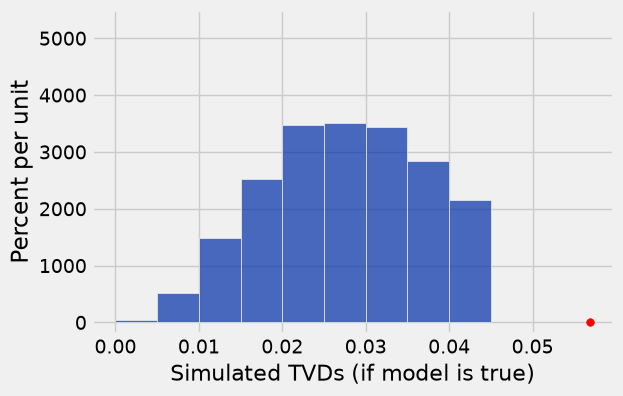

In [42]:
# datascience
title = 'Simulated TVDs (if model is true)'
bins = np.arange(0, .05, .005)

Table().with_column(title, tvds).hist(bins = bins)
print('Observed TVD: ' + str(obsvd_tvd))

# Plotting details; ignore this code
plots.ylim(-2, 55)
plots.scatter(obsvd_tvd, 0, color='red', s=30);

Observed TVD: 0.056881278538812786


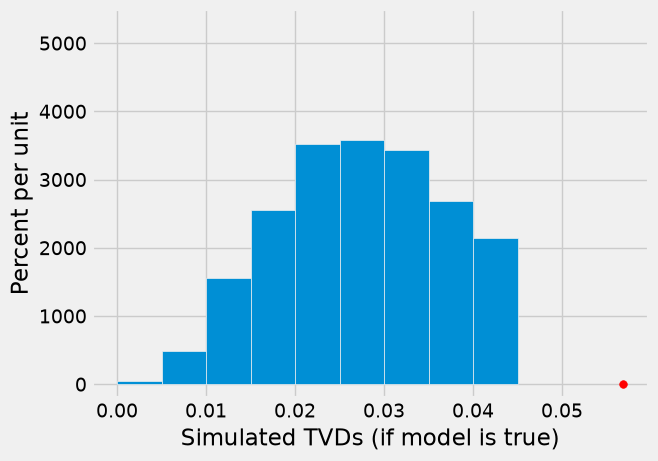

In [43]:
# polars
# matplotlib
title_pl = 'Simulated TVDs (if model is true)'
bins_pl = pl.linear_space(0.0, 0.045, 10, closed="both", eager=True)

_df = pl.DataFrame({title_pl: tvds_pl})
_cols = [c for c in _df.columns if _df[c].dtype.is_numeric()]
if len(_cols) == 1:
    plots.hist(_df.get_column(_cols[0]).to_numpy(), density=True, bins=(lambda _b: _b.to_numpy() if hasattr(_b, 'to_numpy') else _b)(bins_pl))
    plots.xlabel(_cols[0])
else:
    for _col in _cols:
        plots.hist(_df.get_column(_col).to_numpy(), density=True, label=_col, bins=(lambda _b: _b.to_numpy() if hasattr(_b, 'to_numpy') else _b)(bins_pl))
    plots.legend()
plots.ylabel("Percent per unit")
plots.gca().yaxis.set_major_formatter(lambda x, pos: "{:g}".format(100 * x))
print('Observed TVD: ' + str(obsvd_tvd_pl))

# Plotting details; ignore this code
plots.ylim(-2, 55)
plots.scatter(obsvd_tvd_pl, 0, color='red', s=30);